Dataset Shape: (768, 9)

First 5 Records:
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   Pedigree  Age  Outcome  
0     0.627   50        1  
1     0.351   31        0  
2     0.672   32        1  
3     0.167   21        0  
4     2.288   33        1  

Target Distribution:
Outcome
0    500
1    268
Name: count, dtype: int64

Missing Values:
Pregnancies      0
Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
Pedigree         0
Age              0
Outcome          0
dtype: int64

Summary Statistics:
       Pregnancies     Glucose  BloodPressure  SkinThickness 

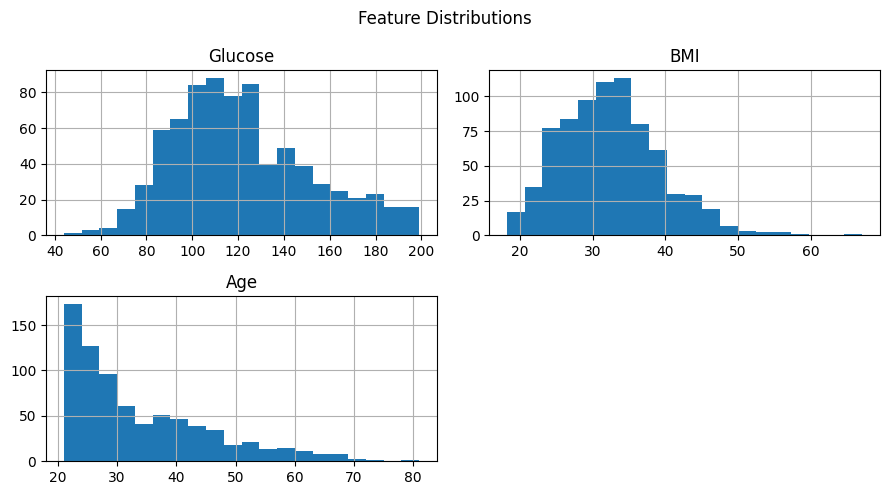


K Value Comparison:
 K  Accuracy  Precision  Recall  F1 Score
 3    0.7208     0.6000  0.6111    0.6055
 5    0.7532     0.6600  0.6111    0.6346
 7    0.7273     0.6250  0.5556    0.5882
 9    0.7403     0.6346  0.6111    0.6226

Selected K: 5

Classification Report:
              precision    recall  f1-score   support

Non-diabetic       0.80      0.83      0.81       100
    Diabetic       0.66      0.61      0.63        54

    accuracy                           0.75       154
   macro avg       0.73      0.72      0.72       154
weighted avg       0.75      0.75      0.75       154



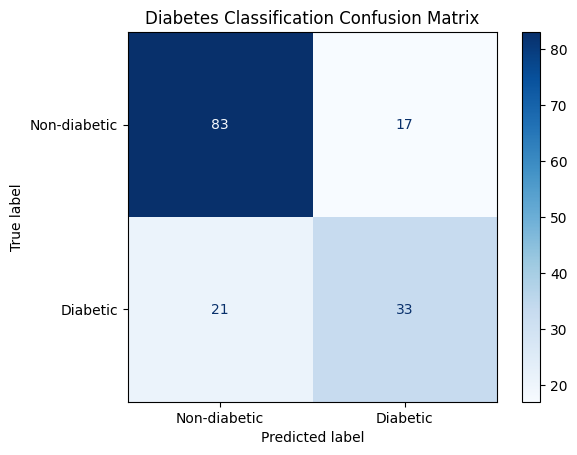

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay,
    classification_report, accuracy_score
)

# 1. Load dataset
# Download diabetes.csv and keep it in the same folder as this program.
df = pd.read_csv("/content/diabetes - diabetes.csv")

print("Dataset Shape:", df.shape)
print("\nFirst 5 Records:")
print(df.head())

# 2. Inspect target and missing values
target = "Outcome"

print("\nTarget Distribution:")
print(df[target].value_counts())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nSummary Statistics:")
print(df.describe())

# 3. Handle invalid zero values
# In these columns, zero generally represents a missing/invalid measurement.
zero_columns = [
    "Glucose", "BloodPressure", "SkinThickness",
    "Insulin", "BMI"
]

print("\nInvalid Zero Counts:")
print((df[zero_columns] == 0).sum())

df[zero_columns] = df[zero_columns].replace(0, np.nan)

# Fill invalid values using each column's median
for col in zero_columns:
    df[col] = df[col].fillna(df[col].median())

# Plot feature distributions
df[["Glucose", "BMI", "Age"]].hist(
    figsize=(9, 5), bins=20
)
plt.suptitle("Feature Distributions")
plt.tight_layout()
plt.show()

# 4. Separate features and target
X = df.drop(columns=[target])
y = df[target]

# 5. Stratified train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 6. Standardize using training data only
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 7. Train KNN models with different K values
k_values = [3, 5, 7, 9]
results = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_scaled, y_train)

    y_pred = model.predict(X_test_scaled)

    results.append({
        "K": k,
        "Accuracy": round(accuracy_score(y_test, y_pred), 4),
        "Precision": round(precision_score(
            y_test, y_pred, zero_division=0
        ), 4),
        "Recall": round(recall_score(
            y_test, y_pred, zero_division=0
        ), 4),
        "F1 Score": round(f1_score(
            y_test, y_pred, zero_division=0
        ), 4)
    })

print("\nK Value Comparison:")
print(pd.DataFrame(results).to_string(index=False))

# 8. Select K with the highest F1-score
f1_scores = [row["F1 Score"] for row in results]

best_index = f1_scores.index(max(f1_scores))
best_k = k_values[best_index]

print("\nSelected K:", best_k)

# Train final model
final_model = KNeighborsClassifier(n_neighbors=best_k)
final_model.fit(X_train_scaled, y_train)

y_pred = final_model.predict(X_test_scaled)

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=["Non-diabetic", "Diabetic"],
    zero_division=0
))

# 9. Display confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-diabetic", "Diabetic"]
)
disp.plot(cmap="Blues")
plt.title("Diabetes Classification Confusion Matrix")
plt.show()
